# Simulation: Source Spike with Propagation

Explain simulation please

## 📦 Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mindmap as mm
import mne_bids

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
**Anatomy**
- `parc`: Parcellation
- `sc`: Distance-based structural connectome
- `fwd`: Forward solution

**Functional**
- `eeg`: EEG template

**Transforms**
- `tkras2ras`: Affine transformation (freesurfer ras -> T1 ras)

🎚️ **<font color=pink>Configuration</font>**:

**Environment configuration**
- `fconfig`: Configuration file.
- `sub`: Subject id (position in list SUBS)

**EEG configuration**
- `duration`: Recording duration in [s]
- `frequency`: Sampling frequency in [Hz]

In [2]:
# ------------ Parameters -------------

# environment
fconfig = "../../papers/simf/configuration.yml"
sub     = "10"

# EEG
duration  = 20
frequency = 250

# -------------------------------------

# configuration
reader = mm.io.dataset_reader(fconfig)

# data
data = reader(sub, "parc", "sc", "fwd", "tkras2ras")
data["eeg"] = mm.sensor.build_eeg_template(duration, frequency)

DATA SUMMARY
Dataset: simf
Subject: 10
Task: None
Run: None
Retrieved objects:
- fwd
- tkras2ras
- parc
- sc
Missing objects:


## 1. ⚙️ Build simulation

#### 1.1 Source

🎚️ **<font color=pink>source parameters</font>**:
- `locations`: Source location (dipole ids or brain region names)
- `waveform_width`: Width of a single wavelet in [s]
- `onset`: Onset time of first wavelet in [s]
- `offset`: Last possible onset time in [s]
- `repeat`: Duration between wavelets in [s] 

In [3]:
# ------------ Parameters -------------

locations      = mm.head.random_region(data["fwd"]["src"], data["parc"], data["tkras2ras"])  # list of dipole ids or brain regions
waveform_width = 0.1        # in [s]
onset          = 0.5        # in [s]
offset         = None       # in [s]
repeat         = 1       # in [s]

# -------------------------------------

source = mm.simulation.Source(
    locations      = locations,
    waveform_width = waveform_width,
    onset          = onset,
    offset         = offset,
    repeat         = repeat,
)

print(source)

Source:
- locations: ['ctx-lh-middletemporal_2']
- waveform width: 0.1 [ms]
- Onset: 0.5 [ms] 
- Offset: None [ms] 
- Repeat: 1 [ms]



📊 **Source waveform**

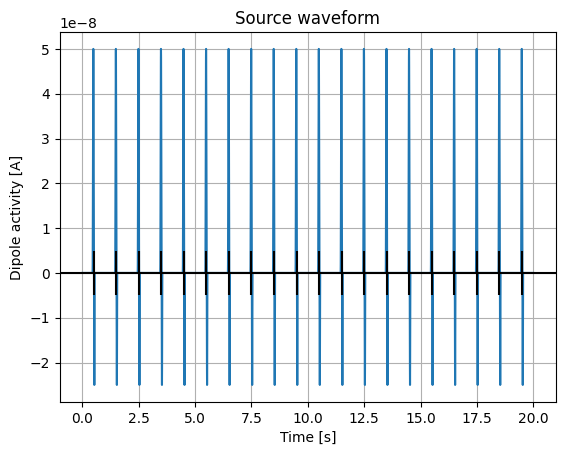

In [4]:
times = data["eeg"].times

plot = source.plot_waveform(times, show_events=True)

📊 **Source locations**

In [5]:
source.plot_targets(data["fwd"]["src"], data["parc"], data["tkras2ras"])

Widget(value='<iframe src="http://localhost:39337/index.html?ui=P_0x7e417dd329d0_0&reconnect=auto" class="pyvi…

#### 1.2 Head Model

The head model class contains all the information about the setup of the simulation. It should contain the sensor information (sensor position, recording times ...) as well as the head information (forward solution, dipole position ...). In addition to these classic requirements for source reconstruction, the head model also contains information about the connectivity between dipoles, measured with tractography:
- connectome weights: structural connections between dipoles measured as fiber densities (NOT IMPLEMENTED YET).
- connectome lengths: average length of fiber tracts between connected dipoles.
- synaptic delay: processing time in [s] at dipoles
- axonal speed: speed of signal traveling through these connections.

<br>
The fiber lengths, together with the synaptic delay and axonal speed, allows us to roughly estimate the delay between a source signal and any other dipole signal in the source space.
<br>

🎚️ **<font color=pink>head model parameters</font>**:
- `synaptic_delay`: synaptic delay in [s]. Summarizes the processing delay at a node.
- `axonal_speed`: axonal speed in [mm/s]. Speed at which the signal travels through axonal connections.

In [6]:
# ------------ Parameters -------------

synaptic_delay = 0.01     # synaptic delay [s] (summarizes the processing delay at a node)
axonal_speed   = 1e5   # axonal speed [mm/s]. Speed at which the signal travels through axonal connections.

# -------------------------------------

hm = mm.simulation.HeadModel(
    sensors            = data["eeg"],
    forward            = data["fwd"],
    connectome_weights = data["sc"]>0,
    connectome_lengths = data["sc"],
    synaptic_delay     = synaptic_delay,
    axonal_speed       = axonal_speed,
    parcellation       = data["parc"],
    tkras2ras          = data["tkras2ras"],
)

print(hm)

Head model:
- Number of dipoles: 7465
- Number of sensors: 203
- Recording duration: 19.996 [s]
- Recording samples: 5000
- Axonal speed: 100000.0 [mm/s]
- Synaptic delay: 0.01 [s]
- Parcellation: 473
- tkras2ras: True 



📊 **Distance to source**

The head model class is usefull for computing distance properties between the source and other dipoles. For example:

🎚️ **<font color=pink>Compute distance</font>**:
- `weight`: Type of distance to measure between a source and all other dipoles. The type can be:
    - `delay`: Measures temporal distance (delay) in [s]
    - `hop`: Measures the graph distance (number of hops)
    - `length`: Measures the physical distance in [mm] to travel along the fiber network.

In [7]:
# ------------ Parameters -------------

weight = "delay"

# -------------------------------------

sources   = np.argwhere(source.select_targets(hm.fwd["src"], hm.parc, hm.cras)).squeeze()
distances = hm.compute_distance_from_source(sources[0], weight=weight)
distances[distances == np.inf] = 0      # Sometimes, nodes are isolated (infinite distance to reach them). Set them to 0 for visualization.

mm.viz.plot_brain(hm.fwd["src"], distances).show()

Widget(value='<iframe src="http://localhost:39337/index.html?ui=P_0x7e408ff9bf90_1&reconnect=auto" class="pyvi…

#### 1.3 Noise

The **Noise** class specifies the type of noise to be applied to different components within the simulation. Currently, the simulator supports noise addition to dipole amplitudes, sensor amplitudes, and delay times. <br>

To define the noise parameters for a given component, create a dictionary containing the keys "component", "category", and "scale". You can define as many noise dictionaries as needed and group them under the Noise class. Components that were omitted when making a Noise object, won't be affected by any noise during the simulation.<br>

🎚️ **<font color=pink>Noise parameters</font>**:
- `noise_dictionary`: A dictionary containing all necessary information to generate noise for a specific component. It must include the following keys:
    - "component": The name of the component the noise will be applied to.
    - "category": The noise type. Available options are ["pink", "white", "violet", "brownian", "blue"].
    - "scale": The amplitude scale of the noise (e.g., "scale": 1e-8 for noise around 1e-8)

In [8]:
# ------------ Parameters -------------

noise_dipole = {
    "component": "dipole",
    "category": "pink",
    "scale": 1e-9,      # dipole activity are of the order 1e-8 [A]
}

noise_sensor = {
    "component": "sensor",
    "category": "white",
    "scale": 1e-6,      # EEG activity are of the order 1e-3 [V]
}

# -------------------------------------

noise = mm.simulation.Noise(noise_dipole, noise_sensor)
print(noise)

Noise:
- 'dipole' noise:
  - category: pink
  - scale: 1e-09
- 'sensor' noise:
  - category: white
  - scale: 1e-06



📊 **Noise only**

🎚️ **<font color=pink>Generate noise</font>**:

To generate noise for a specific component, call the `generate_noise method`, providing:
- `T`: the number of time points,
- `N`: the number of samples (e.g., number of dipoles)
- `component`: the component’s name.

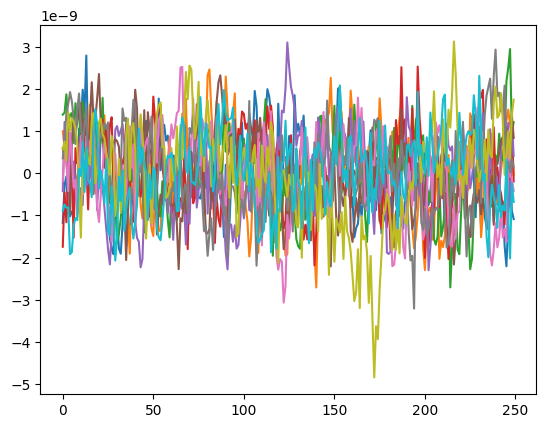

In [9]:

# ------------ Parameters -------------

T = 250
N = 10
component = "dipole"

# -------------------------------------

example = noise.generate_noise(T, N, component)
_ = plt.plot(example.T)

📊 **Signal with added noise**

🎚️ **<font color=pink>Add noise to signal</font>**:

You can also add noise to a signal using the `add_noise` method, providing:
- `signal`: The signal of size (N,T)
- `component`: the name of the component to which the signal belongs to

Text(0.5, 1.0, 'Noisy signal')

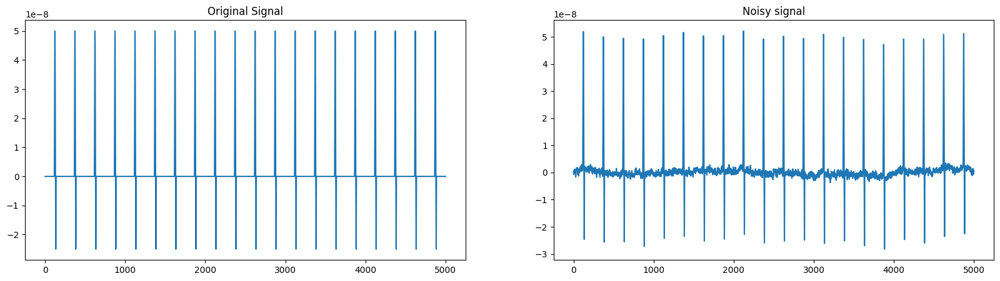

In [10]:
# ------------ Parameters -------------

signal = source.build_waveform(data["eeg"].times)["data"]
component = "dipole"

# -------------------------------------

example = noise.add_noise(signal, component)

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(20,5))

_ = ax1.plot(signal)
ax1.set_title("Original Signal")

_ = ax2.plot(example)
ax2.set_title("Noisy signal")

## ⚙️ 2. Run simulation

The **simulator** orchestrates the behavior of all other classes. During a simulation, each source waveform is propagated to other dipoles by applying a temporal shift—based on delays calculated by the head model—and attenuated using a decay factor, which increases with the number of hops needed for the signal to reach a given dipole. Noise is added to account for uncertainty in the true dipole activity, which may manifest as amplitude noise (variation in signal strength at a given time), temporal noise (uncertainty in the precise timing of the delay), or sensor noise (inaccuracies in the measured signal). <br>

🎚️ **<font color=pink>Run</font>**:
- `w`: decay factor. Number between 0 and 1 describing the amound of signal reaching the next hop. The decay at the n hop is thus w*...*w = w^n. 

In [11]:
# ------------ Parameters -------------

w   = 0.5
snr = 20

# -------------------------------------

# instanciate simulator object
simu = mm.simulation.Simulator(hm, source, noise=noise)

# run simulation
gt, eeg, gtnoise = simu.run(w=w, snr=snr, return_stc_noise=True, recording_type="raw")

print(simu)

Using data from preloaded Raw for 20 events and 225 original time points ...
0 bad epochs dropped
Simulator:
Simulator for source propagation

Head model:
- Number of dipoles: 7465
- Number of sensors: 203
- Recording duration: 19.996 [s]
- Recording samples: 5000
- Axonal speed: 100000.0 [mm/s]
- Synaptic delay: 0.01 [s]
- Parcellation: 473
- tkras2ras: True 

Source:
- locations: ['ctx-lh-middletemporal_2']
- waveform width: 0.1 [ms]
- Onset: 0.5 [ms] 
- Offset: None [ms] 
- Repeat: 1 [ms]

Noise:
- 'dipole' noise:
  - category: pink
  - scale: 1e-09
- 'sensor' noise:
  - category: white
  - scale: 1e-06




📊 **Dipole activity**

In [12]:
print(f"Maximum dipole amplitude: {np.max(np.abs(gt.data))} [A]")

mm.viz.plot_brain(hm.fwd["src"], gtnoise).show()

Maximum dipole amplitude: 9.917482555221614e-09 [A]


Widget(value='<iframe src="http://localhost:39337/index.html?ui=P_0x7e406c30aa90_2&reconnect=auto" class="pyvi…

📊 **Sensor activity**

Using matplotlib as 2D backend.


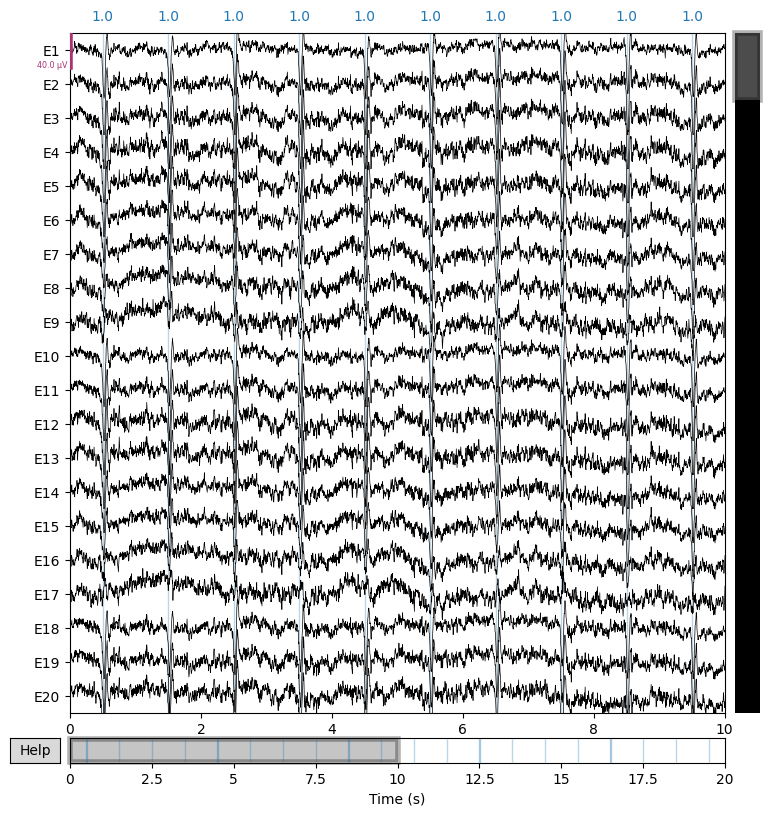

In [13]:
import mne

if isinstance(eeg, mne.Evoked):
    peak_phase = mm.sensor.get_rising_phase(eeg, ratio=1)
    half_phase = mm.sensor.get_rising_phase(eeg, ratio=0.5)

    print("Key time points for source reconstruction:")
    print(f"Peak phase: {peak_phase} [s]")
    print(f"Half rising phase: {half_phase} [s]")

_ = eeg.plot()

💾 **save simulation**

In [14]:
# ------------ Parameters -------------

task = "rest"
run  = 11

# -------------------------------------

# save EEG
feeg = mne_bids.BIDSPath(
    root     = reader.config["DS_DIR"],
    subject  = data["sub"],
    datatype = "eeg",
    task     = task,
    run      = run,
)
mne_bids.write_raw_bids(eeg, feeg, allow_preload=True, format="BrainVision", overwrite=True)

# save ground truth
fgt = mm.io.get_bidspath(
    root     = reader.config["DS_DIR"],
    subject  = data["sub"],
    datatype = "stc",
    task     = task,
    run      = run,
)
mm.io.mkdir(fgt)
gt.save(fgt, overwrite=True)

# save ground truth with noise
fgtnoise = mm.io.get_bidspath(
    root        = reader.config["DS_DIR"],
    subject     = data["sub"],
    datatype    = "stc",
    task        = task,
    run         = run,
    description = "noisy",
)
mm.io.mkdir(fgtnoise)
gtnoise.save(fgtnoise, overwrite=True)

print("\033[92mSuccessfully saved simulation.\033[0m")

Writing '/media/nino/DATA/SIMF/participants.tsv'...
Writing '/media/nino/DATA/SIMF/participants.json'...
Writing '/media/nino/DATA/SIMF/sub-10/eeg/sub-10_space-CapTrak_electrodes.tsv'...
Writing '/media/nino/DATA/SIMF/sub-10/eeg/sub-10_space-CapTrak_coordsystem.json'...
The provided raw data contains annotations, but you did not pass an "event_id" mapping from annotation descriptions to event codes. We will generate arbitrary event codes. To specify custom event codes, please pass "event_id".
Used Annotations descriptions: [np.str_('1.0')]
Writing '/media/nino/DATA/SIMF/sub-10/eeg/sub-10_task-rest_run-11_events.tsv'...
Writing '/media/nino/DATA/SIMF/sub-10/eeg/sub-10_task-rest_run-11_events.json'...
Writing '/media/nino/DATA/SIMF/dataset_description.json'...
Writing '/media/nino/DATA/SIMF/sub-10/eeg/sub-10_task-rest_run-11_eeg.json'...
Found no extension for raw file, assuming "BTi" format and appending extension .pdf
Writing '/media/nino/DATA/SIMF/sub-10/eeg/sub-10_task-rest_run-11_ch

/tmp/ipykernel_38438/1107584858.py:16: RuntimeWarning: Converting data files to BrainVision format
  mne_bids.write_raw_bids(eeg, feeg, allow_preload=True, format="BrainVision", overwrite=True)
/tmp/ipykernel_38438/1107584858.py:16: RuntimeWarning: Encountered data in "double" format. Converting to float32.
  mne_bids.write_raw_bids(eeg, feeg, allow_preload=True, format="BrainVision", overwrite=True)


[done]
Writing STC to disk...
Overwriting existing file.
Overwriting existing file.
[done]
Successfully saved simulation.


In [36]:
import mindmap as mm
import pandas as pd

def make_sim_dataset(
    reader      : mm.io.DatasetReader, 
    subject     : str, 
    regions     : list[str] | list[int],
    params      : dict=None,
    repetitions : int=1,
    root        : str=None,
) -> None:
    """
    Make a dataset of simulated data.

    Parameters:
    -----------
    reader: mm.io.DatasetReader
        Reader to retrieve dataset components:
        - fwd: Forward solution
        - conn: Fiber length connectome
        - ...
    subject: str
        Subject id to use a sample.
    regions: list[str] | list[int]
        List of regions to simulate. The simulation will use these regions as source onsets. If the 
        regions are a list of brain region names, the subject sample needs to be parcellated.
    params:
        Simulations parameters. When a parameter is not provided, it will use the default parameter.
        Parameters are as follows:
        - duration: Duration of 1 simulation in [s].
        - frequency: Recording sampling frequency.
        - source: dictionary with source parameters
            - waveform_width: source waveform width.
            - onset: first waveform apparition in [ms]
            - offset: last waveform apparition in [ms]
            - repeat: time in [ms] between consecutive repetitions.
        - headmodel: dictionary with HeadModel parameters
            - synaptic_delay: Nodal delay in [ms].
            - axonal_speed: Axonal speed in [mm/ms].
        - simulator: dictionary with Simulator parameters.
            - w: Weight decay factor [0-1].
            - snr: Target SNR (peak to baseline SNR).
    repitition: int
        Repetitions per region.
    root: str
        Root directory where to store the data. If None, it will take the root directory
        of the reader as root.
    Saves
    -----
    This function creates new `eeg` and `ave` folders in the root directory in which, for a given subject, 
    will create simulated data. If the number of regions is greater than 1, each simulation will have the 
    BIDS run tag with corresponding to the repetition.
    """
    # -----------
    # load data
    # -----------
    data = reader(subject, "parc", "sc", "fwd", "tkras2ras")
    data["eeg"] = mm.sensor.build_eeg_template(params["duration"], params["frequency"])

    if root is None:
        root = reader.config["DS_DIR"]

    # ------------
    # head model
    # ------------
    hm = mm.simulation.HeadModel(
        sensors = data["eeg"],
        forward = data["fwd"],
        connectome_weights = data["sc"]>0,
        connectome_lengths=data["sc"],
        parcellation = data["parc"],
        tkras2ras = data["tkras2ras"],
        **params["headmodel"],
    )

    # -------------
    # noise model
    # -------------
    noise_dipole = {
        "component": "dipole",
        "category": "pink",
        "scale": 1e-9,      # dipole activity are of the order 1e-8 [A]
    }

    noise_sensor = {
        "component": "sensor",
        "category": "white",
        "scale": 1e-6,      # EEG activity are of the order 1e-3 [V]
    }

    noise = mm.simulation.Noise(noise_dipole, noise_sensor)

    # -----------------------------------
    # Simulate for each source locations
    # -----------------------------------

    # metadata table
    table = pd.DataFrame(columns=["run", "location"])

    # iterate over source locations
    run = 1
    for reg in regions:
        source = mm.simulation.Source(locations = reg, **params["source"])
        simu   = mm.simulation.Simulator(hm, source, noise=noise)

        for rep in range(repetitions):
            # simulate
            gt, eeg, gtnoise = simu.run(return_stc_noise=True, recording_type="raw", **params["simulator"])

            # save result
            feeg = mne_bids.BIDSPath(root=reader.config["DS_DIR"], subject=data["sub"], datatype="eeg", task="rest", run=run)
            mne_bids.write_raw_bids(eeg, feeg, allow_preload=True, format="BrainVision", overwrite=True)

            fgt = mm.io.get_bidspath(root=reader.config["DS_DIR"], subject=data["sub"], datatype="stc", task="rest", run=run)
            mm.io.mkdir(fgt)
            gt.save(fgt, overwrite=True)

            fgtnoise = mm.io.get_bidspath(root=reader.config["DS_DIR"], subject=data["sub"], datatype="stc", task="rest", run=run, description="noisy")
            mm.io.mkdir(fgtnoise)
            gtnoise.save(fgtnoise, overwrite=True)

            # add entries to the metadata table
            table = pd.concat([table, pd.DataFrame([[run, reg]], columns=table.columns)], ignore_index=True)

            # increment run count
            run += 1

    # Save the table in the root directory
    table.to_csv(root/"simulation_metadata.csv")

In [ ]:
dipoles = mm.get_dipole_positions(data["fwd"]["src"])*1000
dipoles = mm.align_freesurfer2subject(dipoles, data["tkras2ras"])

labels = data["parc"].label_points(dipoles)
labels = np.unique(labels)

params = {
    "duration":20,
    "frequency":250,
    "source":{
        "waveform_width":0.1,
        "onset":0.5,
        "offset":None,
        "repeat":1,
    },
    "headmodel":{
        "synaptic_delay":0.01,
        "axonal_speed":1e5,
    },
    "simulator":{
        "w":0.5,
        "snr":10,
    }
}

make_sim_dataset(reader, "10", labels, params, repetitions=10)

In [9]:
import glob
import mindmap as mm
import mne

reader = mm.io.dataset_reader("../../papers/simf/configuration.yml")

subject = "10"
path    = reader.config["DS_DIR"]/f"sub-{subject}"/"eeg"
runs    = len(glob.glob(str(path/"*.eeg")))

tmin     = -0.45
tmax     = 0.45
baseline = [-0.44, -0.2]

for r in range(runs)[:10]:
    data = reader(subject, "eeg", run=r+1, task="rest", verbose=0)
    
    # average referencing
    data["eeg"] = data["eeg"].set_eeg_reference(ref_channels="average", projection=True, verbose="warning")

    # epochs
    events = mne.events_from_annotations(data["eeg"], verbose="warning")[0]
    epochs = mne.Epochs(data["eeg"], events, tmin=tmin, tmax=tmax, baseline=baseline, verbose="warning")

    # evoked
    evoked = epochs.average()

    # save EEG
    file = mm.io.get_bidspath(
        root     = reader.config["MM_DIR"],
        subject  = data["sub"],
        datatype = "ave",
        session  = None,
        task     = data["task"],
        run      = data["run"],
    )
    
    mm.io.mkdir(file)
    evoked.save(file)

    if r+1%100 == 0:
        print(f"Files processed: ({r+1}/{runs})")

In [12]:
200%100

0

## ⚙️ 3. Observe simulation properties

- Peak phase does not correspond to source anymore
- Signal more compact in Fourier after source onset
- Signal to noise ratio

In [59]:
import pygsp
import mindmap as mm

# signal & connectome
signal = gtnoise.data
conn   = (data["sc"] > 0).astype(int)

# compute linear basis
G = pygsp.graphs.Graph(conn, lap_type="normalized")
G.compute_fourier_basis()

U   = G.U
lam = G.e

mm.viz.plot_harmonics(data["fwd"]["src"], U.T).show()

2025-11-04 15:09:54,427:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (7465 x 7465) may take some time.


NameError: name 'mm' is not defined

In [60]:
signal_2 = U.T @ signal
mm.viz.plot_spectrum(signal_2).show()

No times provided


In [61]:
def measure_compactness(signal, basis, percentile = 95):
    """
    Measure compactness as in Rué-Queralt 2023: https://www.sciencedirect.com/science/article/pii/S1053811921008843?via%3Dihub

    Parameters
    ----------
    signal: np.ndarray
        Spatio-temporal signal (N,T)

    basis: np.ndarray (N,N)
        Orthonormal linear transform to project the signal into a compressible space.

    percentile: int [0-100]
        Percentage of compresion (corresponds to the percentage of dimensions to remove)

    Returns
    -------
    corr: float [0-1]
        Correlation between original signal and reconstructed compressed signal. 

    score: float [-inf, 1]
        Similarity (1-rmse) between original signal and reconstructued signal. Technically the score can go to -infty but since we 
        remove energy from the signal when compressing, it should not be possible to reach below 0.
    """

    # -----------------
    # Compress signal
    # -----------------

    # switch to compressible space
    signal2 = basis.T @ signal

    # measure average power accross time for each component
    powers = mm.metric.avg_power(signal2)    

    # mask the X% components (where X% is the percentile) having the least power
    thresh        = np.percentile(powers, percentile) 
    mask          = powers < thresh
    signal2[mask] = 0       # -> compressed signal

    # ---------------------
    # Evaluate compression
    # ---------------------

    # reconstruct signal from compressed information only
    recon = basis @ signal2 

    # compare original with reconstructed

    # correlation
    corr = np.corrcoef(signal.ravel(), recon.ravel())[0,1]

    # 1 - root mean squared error
    score = 1 - (np.linalg.norm(signal-recon, ord="fro")/np.linalg.norm(signal))

    return corr, score

def measure_compactness_dynamics(signal, basis, min_percentile=0):
    """
    Measure compactness dynamics as in Rué-Queralt 2023: https://www.sciencedirect.com/science/article/pii/S1053811921008843?via%3Dihub
    The compactness dynamic is an average compactness accross percentiles for a single time point. This suggests an idea of the compactness over time.

    Parameters
    ----------
    signal: np.ndarray (N,T)
        Spatio-temporal signal

    basis: np.ndarray (N,N)
        Orthonormal linear transform to project the signal into a compressible space.

    min_percentile: int [0-100]
        Minimum percentile to consider.

    Returns
    -------
    corr: float [0-1]
        Average correlation over percentiles between original signal and reconstructed compressed signal. 

    score: float [-inf, 1]
        Average similarity (1-rmse) over percentiles between original signal and reconstructued signal. Technically the score can go to -infty but since we 
        remove energy from the signal when compressing, it should not be possible to reach below 0.
    """

    # -----------------
    # Compute powers
    # -----------------

    # switch to compressible space
    signal2 = basis.T @ signal

    # measure average power accross time for each component
    powers = mm.metric.avg_power(signal2)    

    # ------------------------------------
    # Evaluate compression per time point
    # ------------------------------------

    temporal_corrs  = np.zeros(signal.shape[1])
    temporal_scores = np.zeros(signal.shape[1])

    percentiles = range(min_percentile, 100)

    for p in percentiles:

        # mask the p% components (where X% is the percentile) having the least power
        thresh        = np.percentile(powers, p) 
        mask          = powers < thresh
        signal2[mask] = 0       # -> compressed signal

        # reconstruct signal from compressed information only
        recon = basis @ signal2

        # evaluate each time point

        # correlation
        temporal_corrs += [np.corrcoef(signal[:,i], recon[:,i])[0,1] for i in range(signal.shape[1])]

        # 1 - root mean squared error
        temporal_scores += 1 - (np.linalg.norm(signal-recon, axis=0)/np.linalg.norm(signal, axis=0))

    temporal_corrs  /= len(percentiles)
    temporal_scores /= len(percentiles)

    return temporal_corrs, temporal_scores

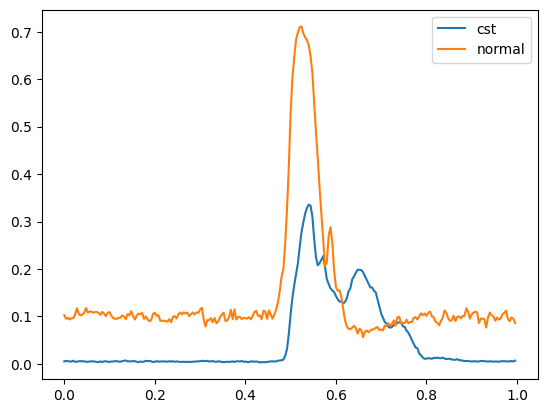

In [62]:
corr_dynamics_cst, score_dynamics_cst = measure_compactness_dynamics(signal, U, min_percentile=99)
corr_dynamics, score_dynamics = measure_compactness_dynamics(signal, np.eye(len(U)), min_percentile=99)


import matplotlib.pyplot as plt 

_ = plt.plot(data["eeg"].times, score_dynamics_cst)
_ = plt.plot(data["eeg"].times, corr_dynamics)
plt.legend(["cst", "normal"])

In [310]:
print(measure_compactness(signal[:,110:150], U, percentile=90))
print(measure_compactness(signal[:,110:150], np.eye(len(U)), percentile=90))

(np.float64(0.7330648357231394), np.float64(0.32241961287673193))
(np.float64(0.7820522122904304), np.float64(0.3791486577387625))
